# Credit Scoring Model: Predicting Credit Card Default

Author: Omar Abdelhady

**Goal.** Predict whether a credit card client will default on next month's payment, using six months of
billing and repayment history. Three classifiers are compared (Logistic Regression, Decision Tree, Random
Forest), with and without class-imbalance handling, and the final model gets a decision threshold chosen
from an explicit business cost.

**Workflow**
1. Load and clean the data
2. Stratified train/test split (the test set is not touched again until Section 9)
3. Exploratory data analysis on the training set only
4. Feature engineering from payment history
5. Leak-free preprocessing inside scikit-learn pipelines
6. Hyperparameter tuning and 5-fold cross-validated model comparison
7. Feature engineering ablation and a check on demographic features
8. Choosing the decision threshold from a 5:1 cost ratio
9. Final evaluation on the held-out test set
10. Feature importance

## 0. Setup
A fixed random seed makes every split, fold and model reproducible. The two cost constants encode the
business assumption used in Section 8: missing a defaulter costs 5 units, wrongly rejecting a good customer
costs 1 unit.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, accuracy_score, confusion_matrix,
                             roc_curve, ConfusionMatrixDisplay)
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
COST_FN = 5   # cost of approving a client who then defaults (missed defaulter)
COST_FP = 1   # cost of rejecting / restricting a client who would have paid

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

# A small, consistent visual style: one color per model, recessive grid.
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Decision Tree": "#eb6834", "Random Forest": "#1baf7a"}
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}          # 0 = paid, 1 = default
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


## 1. Load the data
**Dataset:** UCI *Default of Credit Card Clients* (Yeh and Lien, 2009). 30,000 clients of a Taiwanese bank,
April to September 2005. Target: `default payment next month` (1 = default).

The loader needs no manual download. It tries, in order:
1. a local copy in `data/` if one exists (optional, for offline use),
2. the official UCI repository through `ucimlrepo` (dataset id 350),
3. OpenML through `sklearn.datasets.fetch_openml` (dataset id 42477), as a fallback.

The sources name columns differently (`X1..X23` vs descriptive names), so everything is mapped to the
documented UCI names. Two safeguards make the result identical whichever source is used:
* an assertion checks the known shape (30,000 rows) and number of defaulters (6,636);
* rows are sorted by all columns before splitting, so the train/test split does not depend on the order
  a particular source happens to deliver rows in.

In [2]:
# Documented UCI column order (X1..X23). PAY_0 is renamed PAY_1 below so all six month
# blocks (PAY_k, BILL_AMTk, PAY_AMTk) share the same index k = 1 (Sept 2005) ... 6 (Apr 2005).
UCI_COLUMNS = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
                "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
               + [f"BILL_AMT{i}" for i in range(1, 7)]
               + [f"PAY_AMT{i}" for i in range(1, 7)])
TARGET_NAMES = {"y", "default payment next month", "default.payment.next.month"}
LOCAL_FILE = Path("data") / "default of credit card clients.xls"


def _standardize(df: pd.DataFrame) -> pd.DataFrame:
    # Map any source's column naming onto the UCI names plus a binary `default` target.
    df = df.copy()
    df = df.drop(columns=[c for c in df.columns if str(c).strip().upper() == "ID"])
    target = [c for c in df.columns if str(c).strip().lower() in TARGET_NAMES]
    assert len(target) == 1, f"could not identify target column in {list(df.columns)}"
    y = pd.to_numeric(df.pop(target[0]).astype(str)).astype("int64")
    if [str(c).strip().upper() for c in df.columns] == [f"X{i}" for i in range(1, 24)]:
        df.columns = UCI_COLUMNS                        # ucimlrepo / OpenML style X1..X23
    df = df[UCI_COLUMNS].astype(str).apply(pd.to_numeric).astype("int64")   # also handles categorical dtypes
    df["default"] = y.values
    return df.rename(columns={"PAY_0": "PAY_1"})


def load_credit_default():
    if LOCAL_FILE.exists():
        return _standardize(pd.read_excel(LOCAL_FILE, header=1)), f"local file {LOCAL_FILE}"
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=350)
        raw = pd.concat([ds.data.features, ds.data.targets], axis=1)
        return _standardize(raw), "UCI ML Repository via ucimlrepo (id=350)"
    except Exception as err:
        print(f"ucimlrepo failed ({type(err).__name__}); trying OpenML")
        from sklearn.datasets import fetch_openml
        raw = fetch_openml(data_id=42477, as_frame=True).frame
        return _standardize(raw), "OpenML via fetch_openml (data_id=42477)"


df, source = load_credit_default()

# Integrity check against the published dataset, then an order-independent row order.
assert df.shape == (30000, 24) and df["default"].sum() == 6636, "unexpected dataset contents"
df = df.sort_values(list(df.columns), kind="mergesort").reset_index(drop=True)

print("Loaded from:", source)
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head()

Loaded from: UCI ML Repository via ucimlrepo (id=350)
Shape: (30000, 24) | missing values: 0


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,10000,1,1,1,38,-1,-1,2,0,0,...,9665,10470,10169,5000,0,500,1100,0,1000,1
1,10000,1,1,1,40,2,-1,-1,-2,-2,...,0,0,0,5000,0,0,0,0,0,1
2,10000,1,1,1,41,0,0,3,2,2,...,9169,10056,8559,3000,0,0,1002,0,500,0
3,10000,1,1,1,42,4,3,2,2,2,...,7975,7701,7787,0,0,2000,0,359,331,0
4,10000,1,1,1,48,1,2,0,0,0,...,9000,9000,0,0,2000,2000,0,0,0,0


### 1.1 Cleaning undocumented codes
The documentation defines `EDUCATION` as 1 to 4 (4 = other) and `MARRIAGE` as 1 to 3 (3 = other), but the
data also contains undocumented codes. They are folded into the existing *other* category.

This is a fixed per-row recoding that learns nothing from the data, so it is safe to do before the split.

The repayment status columns `PAY_k` use: -2 = no card usage, -1 = paid in full, 0 = revolving credit
(minimum paid), 1 to 8 = number of months the payment is delayed.

In [3]:
print("EDUCATION before:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE  before:", df["MARRIAGE"].value_counts().sort_index().to_dict())

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})   # undocumented -> other
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})                 # undocumented -> other

print("EDUCATION after: ", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE  after: ", df["MARRIAGE"].value_counts().sort_index().to_dict())

EDUCATION before: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE  before: {0: 54, 1: 13659, 2: 15964, 3: 323}
EDUCATION after:  {1: 10585, 2: 14030, 3: 4917, 4: 468}
MARRIAGE  after:  {1: 13659, 2: 15964, 3: 377}


## 2. Stratified train/test split (before any analysis)
The split happens before EDA and before any fitting, and the test set (20%) is not used again until the final
evaluation. Stratifying on the target keeps the default rate the same in both parts. Everything that learns
from data (scalers, encoders, models, tuning, threshold choice) uses the training set only.

In [4]:
X = df.drop(columns="default")
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"train: {X_train.shape}, default rate {y_train.mean():.4f}")
print(f"test:  {X_test.shape}, default rate {y_test.mean():.4f}")

train: (24000, 23), default rate 0.2212
test:  (6000, 23), default rate 0.2212


## 3. Exploratory data analysis (training set only)
### 3.1 Class balance and the strongest single signal

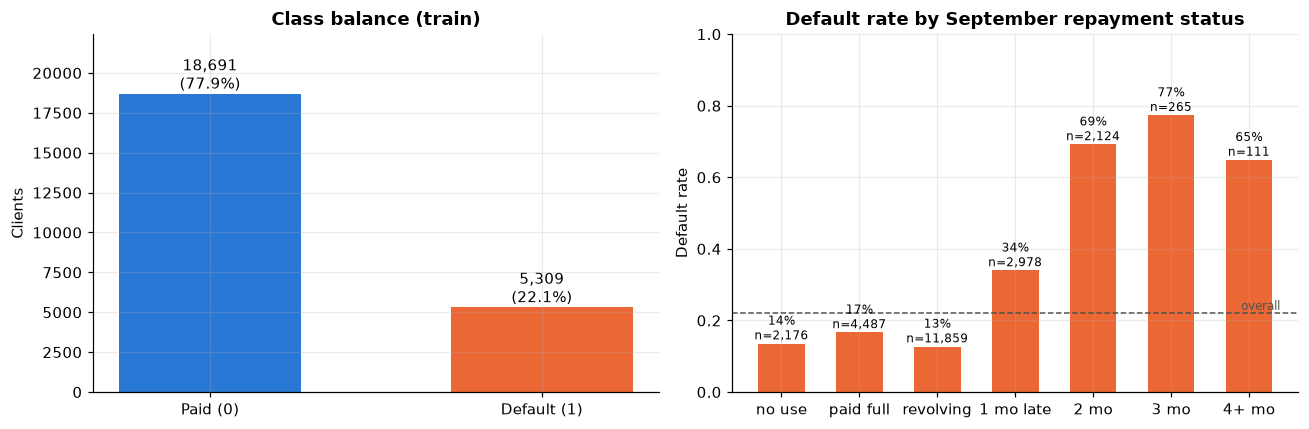

In [5]:
train = X_train.assign(default=y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class balance
counts = train["default"].value_counts().sort_index()
axes[0].bar(["Paid (0)", "Default (1)"], counts.values, color=[CLASS_COLORS[0], CLASS_COLORS[1]], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].set_title("Class balance (train)"); axes[0].set_ylabel("Clients")

# Default rate by most recent repayment status (PAY_1, September)
status = train["PAY_1"].clip(upper=4)
labels = {-2: "no use", -1: "paid full", 0: "revolving", 1: "1 mo late", 2: "2 mo", 3: "3 mo", 4: "4+ mo"}
rate = train.groupby(status)["default"].agg(["mean", "size"])
axes[1].bar([labels[k] for k in rate.index], rate["mean"], color=CLASS_COLORS[1], width=0.6)
for i, (m, n) in enumerate(rate.values):
    axes[1].text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
axes[1].axhline(train["default"].mean(), color="#52514e", ls="--", lw=1)
axes[1].text(6.4, train["default"].mean(), "overall", va="bottom", ha="right", fontsize=8, color="#52514e")
axes[1].set_ylim(0, 1); axes[1].set_title("Default rate by September repayment status")
axes[1].set_ylabel("Default rate")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_balance_status.png", bbox_inches="tight"); plt.show()

**Observations.**
* The classes are imbalanced (about 22% defaulters). A model that always predicts "no default" would already
  reach about 78% accuracy while catching zero defaulters, which is why accuracy is not used to judge models.
* Recent repayment behaviour is by far the strongest signal: clients who are already 2 or more months late in
  September default far more often than clients who pay in full or revolve. This motivates the
  delay-based engineered features in Section 4.

### 3.2 Distributions of the money variables
Credit limits, bills and payments are heavily right-skewed (a few very large values), so they are shown on a
log scale. The same observation is why the modeling pipeline applies a log transform to them before scaling.

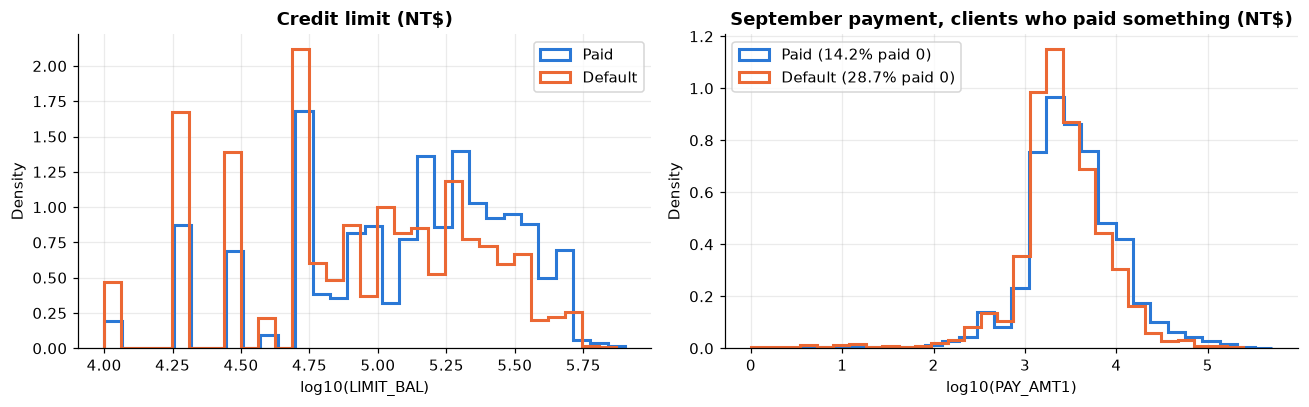

         LIMIT_BAL  PAY_AMT1  BILL_AMT1
default                                
paid      150000.0    2500.0    23589.0
default    90000.0    1600.0    20226.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, title in [(axes[0], "LIMIT_BAL", "Credit limit (NT$)"),
                       (axes[1], "PAY_AMT1", "September payment, clients who paid something (NT$)")]:
    for cls, name in [(0, "Paid"), (1, "Default")]:
        vals = train.loc[train["default"] == cls, col]
        label = name
        if col == "PAY_AMT1":                 # zero payments are reported separately, not plotted
            label = f"{name} ({(vals == 0).mean():.1%} paid 0)"
            vals = vals[vals > 0]
        ax.hist(np.log10(vals), bins=30, density=True, histtype="step", lw=2,
                color=CLASS_COLORS[cls], label=label)
    ax.set_title(title); ax.set_xlabel(f"log10({col})"); ax.set_ylabel("Density"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_distributions.png", bbox_inches="tight"); plt.show()

print(train.groupby("default")[["LIMIT_BAL", "PAY_AMT1", "BILL_AMT1"]].median().rename(index={0: "paid", 1: "default"}))

**Observations.** Defaulters have lower credit limits (median 90,000 vs 150,000 NT$; the bank had already
judged them riskier) and are about twice as likely to have paid nothing in September (see the legend). Among
clients who did pay, the two distributions overlap heavily, so the payment *amount* alone says little; what
matters is the amount relative to what was owed, which motivates the payment-to-bill ratios in Section 4.

### 3.3 Correlations
Spearman (rank) correlation is used because the money variables are skewed and the status codes are ordinal.

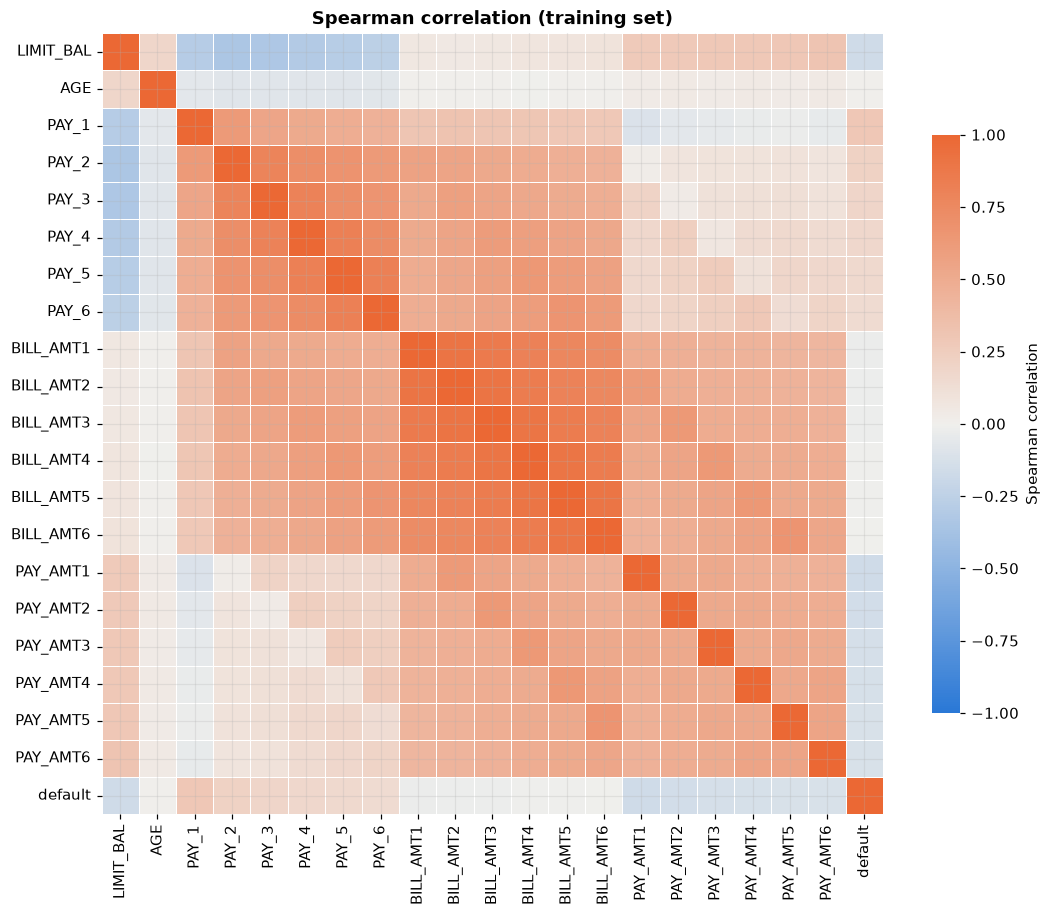

Correlation with default (top 8 by absolute value):
PAY_1        0.294
PAY_2        0.218
PAY_3        0.195
PAY_4        0.173
LIMIT_BAL   -0.167
PAY_AMT1    -0.167
PAY_5        0.160
PAY_AMT2    -0.153


In [7]:
num_cols = [c for c in X_train.columns if c not in ("SEX", "EDUCATION", "MARRIAGE")]
corr = train[num_cols + ["default"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            linecolor="white", cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlation (training set)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_correlation.png", bbox_inches="tight"); plt.show()

print("Correlation with default (top 8 by absolute value):")
print(corr["default"].drop("default").sort_values(key=np.abs, ascending=False).head(8).round(3).to_string())

**Observations.**
* The six monthly bill amounts are strongly correlated with each other (Spearman 0.73 to 0.91), and the six
  repayment status columns are correlated too. Much of the raw information is redundant; summary features
  (averages, counts, ratios) can express it more compactly.
* Repayment status is the group most correlated with default, led by the most recent month (`PAY_1`, 0.29).
  Credit limit and recent payment amounts are negatively correlated (higher limit or larger payment, lower
  risk). Raw bill amounts have almost no correlation with default on their own (|rho| < 0.03); they only
  become informative relative to the credit limit (utilization).

## 4. Feature engineering from payment history
Each feature below is computed **from a single client's own row** using fixed formulas and fixed constants
(no means, quantiles or other statistics learned from the data). That is why it can be applied to the training
and test sets separately without any leakage.

| Feature | Formula | Why it should matter for credit risk |
|---|---|---|
| `util_latest` | BILL_AMT1 / LIMIT_BAL | Credit utilization: a client close to (or over) the limit has little slack and is financially stretched. |
| `util_avg`, `util_max` | mean / max of BILL_AMTk / LIMIT_BAL | Sustained or peak high utilization is a stronger signal than one month. |
| `delay_avg` | mean of max(PAY_k, 0) | Average months of delay; -2/-1/0 all mean "not late", so they count as 0. |
| `delay_max` | max of max(PAY_k, 0) | Worst delinquency in the window: one serious delay is a red flag. |
| `n_late_months` | count of PAY_k >= 1 | Frequency of lateness: a habitual late payer is riskier than a one-off. |
| `n_paid_full` | count of PAY_k == -1 | Months paid in full: a sign of a transactor, typically low risk. |
| `delay_trend` | mean delay (Jul to Sep) minus mean delay (Apr to Jun) | Is the client getting worse? Deteriorating behaviour precedes default. |
| `pay_ratio_latest`, `pay_ratio_avg` | PAY_AMTk / BILL_AMT(k+1), capped to [0, 1] | Share of the previous statement actually repaid. Paying 5% of a bill is very different from paying it all, whatever the amounts. |
| `n_low_pay_months` | count of months with pay ratio < 10% | Repeatedly paying only a small part of the bill indicates rising debt. |
| `bill_growth` | (BILL_AMT1 - BILL_AMT6) / LIMIT_BAL | Balance growing relative to the limit means debt is accumulating. |

Notes on the details:
* The payment made in month k (PAY_AMTk) settles the statement of the month before (BILL_AMT(k+1)), so the
  ratio pairs them that way; this gives five ratios for six months.
* When the previous bill is zero or negative (nothing owed), the ratio is set to 1 (nothing to repay, so
  nothing missed).
* Utilization is clipped to [0, 3]: negative bills mean a credit balance (no debt), and the cap of 3 limits the
  influence of a handful of extreme values (the 99.9th percentile is around 2). These are fixed constants,
  not learned from the data.

In [8]:
STATUS = [f"PAY_{k}" for k in range(1, 7)]
BILL = [f"BILL_AMT{k}" for k in range(1, 7)]
PAYAMT = [f"PAY_AMT{k}" for k in range(1, 7)]


def add_features(data: pd.DataFrame) -> pd.DataFrame:
    # Return a copy of `data` with the engineered payment-history features added (row-wise only).
    out = data.copy()
    limit = out["LIMIT_BAL"]

    # Utilization (debt relative to credit limit)
    util = out[BILL].div(limit, axis=0).clip(0, 3)
    out["util_latest"] = util["BILL_AMT1"]
    out["util_avg"] = util.mean(axis=1)
    out["util_max"] = util.max(axis=1)

    # Delinquency (months late; -2, -1, 0 all count as "not late")
    delay = out[STATUS].clip(lower=0)
    out["delay_avg"] = delay.mean(axis=1)
    out["delay_max"] = delay.max(axis=1)
    out["n_late_months"] = (out[STATUS] >= 1).sum(axis=1)
    out["n_paid_full"] = (out[STATUS] == -1).sum(axis=1)
    out["delay_trend"] = delay[STATUS[:3]].mean(axis=1) - delay[STATUS[3:]].mean(axis=1)

    # Repayment ratio: payment in month k vs. statement of month k+1
    ratios = []
    for k in range(1, 6):
        bill_prev = out[f"BILL_AMT{k + 1}"]
        r = np.where(bill_prev > 0, out[f"PAY_AMT{k}"] / bill_prev.where(bill_prev > 0, 1), 1.0)
        ratios.append(np.clip(r, 0, 1))
    ratios = np.column_stack(ratios)
    out["pay_ratio_latest"] = ratios[:, 0]
    out["pay_ratio_avg"] = ratios.mean(axis=1)
    out["n_low_pay_months"] = (ratios < 0.10).sum(axis=1)

    # Balance trend relative to the limit
    out["bill_growth"] = (out["BILL_AMT1"] - out["BILL_AMT6"]) / limit
    return out


X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
ENGINEERED = [c for c in X_train_fe.columns if c not in X_train.columns]
print(f"{len(ENGINEERED)} engineered features:", ENGINEERED)
X_train_fe[ENGINEERED].describe().T.round(3)

12 engineered features: ['util_latest', 'util_avg', 'util_max', 'delay_avg', 'delay_max', 'n_late_months', 'n_paid_full', 'delay_trend', 'pay_ratio_latest', 'pay_ratio_avg', 'n_low_pay_months', 'bill_growth']


,count,mean,std,min,25%,50%,75%,max
util_latest,24000.0,0.426,0.409,0.000,0.022,0.321,0.835,3.000
util_avg,24000.0,0.376,0.351,0.000,0.032,0.288,0.692,3.000
util_max,24000.0,0.498,0.427,0.000,0.073,0.437,0.926,3.000
delay_avg,24000.0,0.283,0.608,0.000,0.000,0.000,0.333,6.000
delay_max,24000.0,0.685,1.079,0.000,0.000,0.000,2.000,8.000
n_late_months,24000.0,0.839,1.562,0.000,0.000,0.000,1.000,6.000
n_paid_full,24000.0,1.142,1.918,0.000,0.000,0.000,2.000,6.000
delay_trend,24000.0,0.090,0.574,-5.333,0.000,0.000,0.000,3.333
pay_ratio_latest,24000.0,0.399,0.439,0.000,0.045,0.100,1.000,1.000
pay_ratio_avg,24000.0,0.407,0.400,0.000,0.048,0.189,0.819,1.000


### 4.1 Do the engineered features separate the classes?
A quick sanity check on the training set: default rate by number of late months and by utilization band.

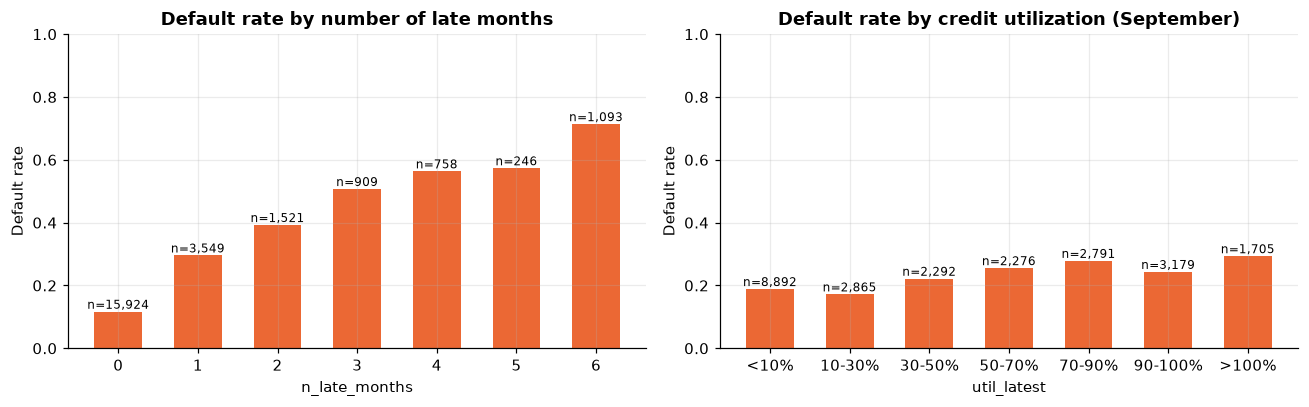

In [9]:
tr = X_train_fe.assign(default=y_train)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

r1 = tr.groupby("n_late_months")["default"].agg(["mean", "size"])
axes[0].bar(r1.index.astype(str), r1["mean"], color=CLASS_COLORS[1], width=0.6)
for i, (m, n) in enumerate(r1.values):
    axes[0].text(i, m, f"n={int(n):,}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("Default rate by number of late months"); axes[0].set_xlabel("n_late_months")
axes[0].set_ylabel("Default rate"); axes[0].set_ylim(0, 1)

bands = pd.cut(tr["util_latest"], [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 3.0],
               labels=["<10%", "10-30%", "30-50%", "50-70%", "70-90%", "90-100%", ">100%"])
r2 = tr.groupby(bands, observed=True)["default"].agg(["mean", "size"])
axes[1].bar(r2.index.astype(str), r2["mean"], color=CLASS_COLORS[1], width=0.6)
for i, (m, n) in enumerate(r2.values):
    axes[1].text(i, m, f"n={int(n):,}", ha="center", va="bottom", fontsize=8)
axes[1].set_title("Default rate by credit utilization (September)"); axes[1].set_xlabel("util_latest")
axes[1].set_ylabel("Default rate"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIG_DIR / "fe_signal.png", bbox_inches="tight"); plt.show()

* `n_late_months` is strongly and monotonically related to risk: the default rate rises from 11.6% for clients
  never late to 71.4% for clients late in all six months.
* Utilization is a weaker, noisier signal: about 17% to 19% default below 30% utilization, rising to roughly
  25% to 29% above 50%, but not strictly increasing (the 90% to 100% band dips to 24.3%). It is kept because
  it adds information the delay features do not carry (how stretched the client is), and Section 10 confirms
  it contributes modestly.

## 5. Leak-free preprocessing pipeline
**Feature set.** `SEX`, `MARRIAGE` and `AGE` are excluded from the main models. In real lending, sex, marital
status and age are protected characteristics under fair-lending rules in many jurisdictions (for example the
US Equal Credit Opportunity Act), so a production credit model should not use them directly. Section 7.2
measures what this costs in predictive performance. `EDUCATION` is kept as a categorical feature.

**Preprocessing**, all inside a scikit-learn `Pipeline` so that in every CV fold and in the final fit the scaler
and encoder are fitted on training rows only:
* money columns (limit, bills, payments): signed `log1p` (a fixed, stateless transform that tames skew), then `StandardScaler`;
* other numeric columns (status codes and engineered features): `StandardScaler`;
* `EDUCATION`: `OneHotEncoder(handle_unknown="ignore")`.

Scaling matters for Logistic Regression (regularization and optimization are scale sensitive). Trees are
invariant to monotonic transforms, so the same preprocessing is harmless for them and keeps the comparison
on identical inputs.

In [10]:
DEMOGRAPHIC = ["SEX", "MARRIAGE", "AGE"]
MONEY = ["LIMIT_BAL"] + BILL + PAYAMT


def signed_log1p(x):
    # log transform that also handles the few negative bill amounts
    return np.sign(x) * np.log1p(np.abs(x))


def build_preprocessor(features):
    # ColumnTransformer for the given feature list; columns not listed are dropped.
    cat = [c for c in features if c in ("EDUCATION", "SEX", "MARRIAGE")]
    money = [c for c in features if c in MONEY]
    other = [c for c in features if c not in cat + money]
    return ColumnTransformer([
        ("money", Pipeline([("slog", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                            ("scale", StandardScaler())]), money),
        ("num", StandardScaler(), other),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])


RAW_FEATURES = [c for c in X_train.columns if c not in DEMOGRAPHIC]
FEATURES = RAW_FEATURES + ENGINEERED                 # main feature set
print(f"Main feature set: {len(FEATURES)} columns ({len(RAW_FEATURES)} raw + {len(ENGINEERED)} engineered)")


def make_pipeline(model_name, balanced, features=FEATURES, **params):
    # Pipeline = preprocessing + classifier. `balanced` switches class_weight="balanced" on/off.
    cw = "balanced" if balanced else None
    if model_name == "Logistic Regression":
        clf = LogisticRegression(max_iter=3000, class_weight=cw, **params)
    elif model_name == "Decision Tree":
        clf = DecisionTreeClassifier(class_weight=cw, random_state=RANDOM_STATE, **params)
    elif model_name == "Random Forest":
        clf = RandomForestClassifier(n_estimators=300, class_weight=cw, n_jobs=-1,
                                     random_state=RANDOM_STATE, **params)
    return Pipeline([("prep", build_preprocessor(features)), ("clf", clf)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Main feature set: 32 columns (20 raw + 12 engineered)


## 6. Model training and cross-validated comparison
### 6.1 Light hyperparameter tuning (training set, 5-fold CV, ROC-AUC)
An unconstrained decision tree memorizes the training data, so each model gets a small grid over its main
complexity control. Tuning uses ROC-AUC because it measures ranking quality independently of any threshold.
The search runs with `class_weight="balanced"`, and the chosen settings are reused in both imbalance settings
so that the with/without comparison changes exactly one thing.

In [11]:
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    "Decision Tree": {"clf__max_depth": [4, 6, 8, 10], "clf__min_samples_leaf": [50, 100]},
    "Random Forest": {"clf__max_depth": [10, None], "clf__min_samples_leaf": [5, 20]},
}

best_params = {}
for name, grid in param_grids.items():
    search = GridSearchCV(make_pipeline(name, balanced=True), grid, scoring="roc_auc", cv=cv, n_jobs=1)
    search.fit(X_train_fe, y_train)
    best_params[name] = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:20s} best {best_params[name]}  CV ROC-AUC = {search.best_score_:.4f}")

Logistic Regression  best {'C': 10.0}  CV ROC-AUC = 0.7690


Decision Tree        best {'max_depth': 6, 'min_samples_leaf': 100}  CV ROC-AUC = 0.7719


Random Forest        best {'max_depth': 10, 'min_samples_leaf': 20}  CV ROC-AUC = 0.7863


### 6.2 Comparison with and without class-imbalance handling
Six configurations (3 models x {no weighting, `class_weight="balanced"`}) are evaluated with the same 5 folds.
Precision, recall and F1 are for the default class at the standard 0.5 threshold; ROC-AUC and PR-AUC
(average precision) are threshold free. PR-AUC is included because it focuses on the minority class.

In [12]:
SCORING = {"precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = []
for name in param_grids:
    for balanced in (False, True):
        pipe = make_pipeline(name, balanced, **best_params[name])
        cvres = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring=SCORING, n_jobs=1)
        row = {"model": name, "class_weight": "balanced" if balanced else "none"}
        for m in SCORING:
            row[m] = cvres[f"test_{m}"].mean()
            row[m + "_std"] = cvres[f"test_{m}"].std()
        rows.append(row)

cv_results = pd.DataFrame(rows)
cv_results.to_csv(RES_DIR / "cv_comparison.csv", index=False)

# Display as "mean ± std"
show = cv_results[["model", "class_weight"]].copy()
for m in SCORING:
    show[m] = [f"{a:.3f} ± {s:.3f}" for a, s in zip(cv_results[m], cv_results[m + "_std"])]
show

,model,class_weight,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,none,0.656 ± 0.012,0.316 ± 0.011,0.427 ± 0.012,0.766 ± 0.006,0.523 ± 0.007
1,Logistic Regression,balanced,0.453 ± 0.008,0.629 ± 0.011,0.527 ± 0.008,0.769 ± 0.004,0.518 ± 0.006
2,Decision Tree,none,0.673 ± 0.012,0.358 ± 0.017,0.467 ± 0.015,0.771 ± 0.003,0.533 ± 0.008
3,Decision Tree,balanced,0.455 ± 0.009,0.634 ± 0.024,0.530 ± 0.006,0.772 ± 0.004,0.534 ± 0.009
4,Random Forest,none,0.675 ± 0.007,0.373 ± 0.006,0.480 ± 0.005,0.787 ± 0.005,0.563 ± 0.009
5,Random Forest,balanced,0.482 ± 0.012,0.626 ± 0.015,0.544 ± 0.010,0.786 ± 0.005,0.561 ± 0.010


In [13]:
best_row = cv_results.loc[cv_results["roc_auc"].idxmax()]
BEST_MODEL = best_row["model"]
BEST_BALANCED = best_row["class_weight"] == "balanced"
print(f"Best by mean CV ROC-AUC: {BEST_MODEL} (class_weight={best_row['class_weight']}), "
      f"ROC-AUC = {best_row['roc_auc']:.4f} ± {best_row['roc_auc_std']:.4f}")

# How much did class weighting change each model?
pivot = cv_results.pivot(index="model", columns="class_weight", values=["recall", "precision", "f1", "roc_auc"])
pivot.round(3)

Best by mean CV ROC-AUC: Random Forest (class_weight=none), ROC-AUC = 0.7866 ± 0.0049


recall        precision              f1         roc_auc  \
class_weight        balanced   none  balanced   none balanced   none balanced   
model                                                                           
Decision Tree          0.634  0.358     0.455  0.673    0.530  0.467    0.772   
Logistic Regression    0.629  0.316     0.453  0.656    0.527  0.427    0.769   
Random Forest          0.626  0.373     0.482  0.675    0.544  0.480    0.786   

                            
class_weight          none  
model                       
Decision Tree        0.771  
Logistic Regression  0.766  
Random Forest        0.787

**Reading the comparison.**
* **Class weighting moves the operating point, not the ranking quality.** With `balanced` weights every model
  predicts "default" far more often at the 0.5 threshold: recall roughly doubles (from 0.32 to 0.37 up to
  about 0.63) while precision drops (from about 0.66 to 0.68 down to 0.45 to 0.48), and F1 improves. ROC-AUC
  and PR-AUC change by at most 0.005, which is within one standard deviation across folds. In other words,
  weighting is roughly equivalent to lowering the threshold. That is why Section 8 chooses the threshold
  explicitly instead of relying on either weighting or the default 0.5.
* **Model ranking.** The Random Forest ranks clients best (ROC-AUC about 0.787, PR-AUC about 0.56). The tuned
  depth-6 Decision Tree and Logistic Regression are close to each other, about 0.015 to 0.021 ROC-AUC behind.
* **Selection.** The selection rule is "highest mean CV ROC-AUC", which picks the Random Forest **without**
  weighting. Its margin over the weighted forest is far smaller than the fold-to-fold spread, so the two are
  effectively tied; the unweighted one is kept because the cost-based threshold handles the imbalance
  directly and its probabilities are not artificially shifted.

## 7. Two checks on the feature set
### 7.1 Ablation: does feature engineering help?
Same CV folds, same tuned settings, `balanced` weights; only the feature list changes.

In [14]:
abl = []
for name in ["Logistic Regression", "Random Forest"]:
    for label, feats in [("raw only", RAW_FEATURES), ("raw + engineered", FEATURES)]:
        pipe = make_pipeline(name, True, features=feats, **best_params[name])
        s = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=1)
        abl.append({"model": name, "features": label, "n_features": len(feats),
                    "roc_auc": s["test_roc_auc"].mean(), "roc_auc_std": s["test_roc_auc"].std(),
                    "pr_auc": s["test_average_precision"].mean()})
ablation = pd.DataFrame(abl)
ablation.to_csv(RES_DIR / "fe_ablation.csv", index=False)
ablation.round(4)

,model,features,n_features,roc_auc,roc_auc_std,pr_auc
0,Logistic Regression,raw only,20,0.7490,0.0064,0.5015
1,Logistic Regression,raw + engineered,32,0.7690,0.0041,0.5184
2,Random Forest,raw only,20,0.7824,0.0054,0.5582
3,Random Forest,raw + engineered,32,0.7863,0.0050,0.5613


**Result.** The engineered features raise Logistic Regression's CV ROC-AUC by about 0.020 (0.749 to 0.769),
but the Random Forest by only about 0.004. This is expected: a linear model cannot build thresholds,
counts or ratios by itself, so it benefits most from having them supplied, while a forest can partly
approximate them from the raw columns. The features also make the models easier to explain (see Section 10).

### 7.2 Cost of excluding demographic features
The best configuration is re-run with `SEX`, `MARRIAGE` and `AGE` added back.

In [15]:
with_demo = FEATURES + DEMOGRAPHIC
s_demo = cross_validate(make_pipeline(BEST_MODEL, BEST_BALANCED, features=with_demo, **best_params[BEST_MODEL]),
                        X_train_fe, y_train, cv=cv, scoring="roc_auc", n_jobs=1)["test_score"]
print(f"{BEST_MODEL}: CV ROC-AUC without demographics = {best_row['roc_auc']:.4f}, "
      f"with demographics = {s_demo.mean():.4f} (difference {s_demo.mean() - best_row['roc_auc']:+.4f})")

Random Forest: CV ROC-AUC without demographics = 0.7866, with demographics = 0.7873 (difference +0.0007)


**Result.** Adding sex, marital status and age changes CV ROC-AUC by less than 0.001, far below the fold-to-fold
spread. Excluding them costs essentially nothing, so the main models keep them out.

## 8. Choosing the decision threshold from business costs
**The two errors are not equally expensive.**
* **False negative (missed defaulter):** the bank approves or keeps extending credit to a client who then
  defaults. It loses the outstanding balance minus whatever collections recover, plus collection costs. This
  is a loss of *principal*.
* **False positive (good client flagged):** the bank rejects, restricts or reviews a client who would have paid.
  It loses the interest and fee margin that client would have generated, and some goodwill. This is a loss of
  *profit*, which is typically much smaller than the principal at risk.

**Assumption:** a missed defaulter costs 5 times as much as a wrongly flagged good client (`COST_FN = 5`,
`COST_FP = 1`). The exact ratio depends on a bank's loss-given-default and margins; 5:1 is a common,
deliberately simple assumption for unsecured credit.

With these costs, a client should be flagged when the expected cost of approving exceeds the expected cost of
rejecting, that is when p x 5 > (1 - p) x 1, giving p > 1/6 (about 0.17). That theoretical value only holds
for well-calibrated probabilities, so the threshold is chosen **empirically** instead: it minimizes the
average cost on **out-of-fold** predictions for the training set (each client is scored by a model that did
not see it during training). The test set is not used to pick it.

Chosen threshold: 0.17  (out-of-fold average cost 0.5455 per client vs 0.7334 at 0.50)
Out-of-fold at chosen threshold: precision 0.392, recall 0.735, F1 0.511
Approve everyone: 1.1060 per client | Reject everyone: 0.7788 per client


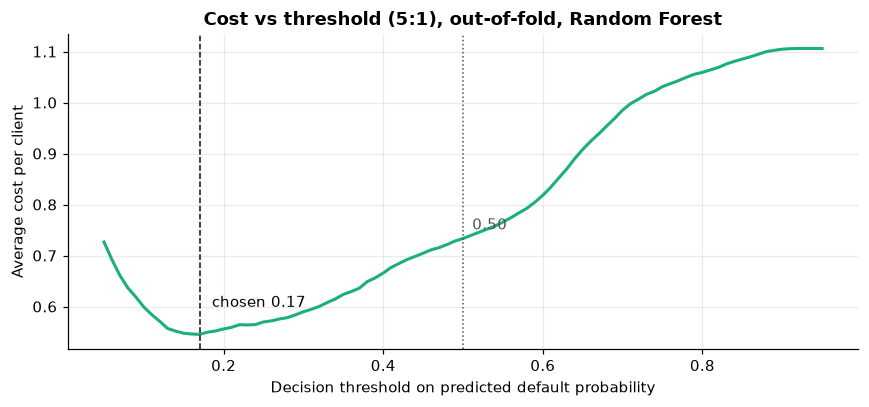

In [16]:
best_pipe = make_pipeline(BEST_MODEL, BEST_BALANCED, **best_params[BEST_MODEL])
oof_proba = cross_val_predict(best_pipe, X_train_fe, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]


def cost_per_client(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return (COST_FN * fn + COST_FP * fp) / len(y_true)


thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
costs = np.array([cost_per_client(y_train, oof_proba, t) for t in thresholds])
THRESHOLD = float(thresholds[costs.argmin()])

cost_at_05 = cost_per_client(y_train, oof_proba, 0.5)
oof_pred = (oof_proba >= THRESHOLD).astype(int)
print(f"Chosen threshold: {THRESHOLD:.2f}  (out-of-fold average cost {costs.min():.4f} per client "
      f"vs {cost_at_05:.4f} at 0.50)")
print(f"Out-of-fold at chosen threshold: precision {precision_score(y_train, oof_pred):.3f}, "
      f"recall {recall_score(y_train, oof_pred):.3f}, F1 {f1_score(y_train, oof_pred):.3f}")

# Reference: cost of the two trivial policies
print(f"Approve everyone: {COST_FN * y_train.mean():.4f} per client | "
      f"Reject everyone: {COST_FP * (1 - y_train.mean()):.4f} per client")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(thresholds, costs, color=MODEL_COLORS[BEST_MODEL], lw=2)
ax.axvline(THRESHOLD, color="#0b0b0b", lw=1, ls="--")
ax.axvline(0.5, color="#52514e", lw=1, ls=":")
ax.annotate(f"chosen {THRESHOLD:.2f}", (THRESHOLD, costs.min()), xytext=(8, 18), textcoords="offset points")
ax.annotate("0.50", (0.5, cost_at_05), xytext=(6, 6), textcoords="offset points", color="#52514e")
ax.set_xlabel("Decision threshold on predicted default probability")
ax.set_ylabel("Average cost per client")
ax.set_title(f"Cost vs threshold (5:1), out-of-fold, {BEST_MODEL}")
plt.tight_layout(); plt.savefig(FIG_DIR / "threshold_cost.png", bbox_inches="tight"); plt.show()

**Result.** The empirical minimum lands at 0.17, the same as the theoretical 1/6, which suggests the unweighted
forest's probabilities are reasonably calibrated. Compared with the default 0.5, the chosen threshold cuts the
out-of-fold cost per client by about a quarter, by catching many more defaulters at the price of more false
alarms. Both trivial policies (approve everyone, reject everyone) cost far more than the model.

## 9. Final evaluation on the held-out test set
Each model is refitted on the full training set with its tuned settings and with whichever class-weight setting
scored the higher CV ROC-AUC in Section 6.2, then scored once on the test set. Two reference points are
included:
* **Rule baseline:** flag anyone whose September payment is at least one month late (`PAY_1 >= 1`), a simple
  rule a bank might use without a model;
* the **best model at the cost-based threshold** chosen in Section 8.

In [17]:
# Per model: the class-weight setting that won that model's own CV comparison
SELECTED_BALANCED = {name: cv_results[cv_results["model"] == name].sort_values("roc_auc").iloc[-1]["class_weight"] == "balanced"
                     for name in param_grids}
cw_label = lambda b: "balanced" if b else "no weighting"
print({k: cw_label(v) for k, v in SELECTED_BALANCED.items()})

fitted, test_proba = {}, {}
for name, bal in SELECTED_BALANCED.items():
    pipe = make_pipeline(name, bal, **best_params[name]).fit(X_train_fe, y_train)
    fitted[name], test_proba[name] = pipe, pipe.predict_proba(X_test_fe)[:, 1]
best_test_proba = test_proba[BEST_MODEL]      # same configuration as used for the threshold in Section 8


def evaluate(label, y_true, pred, proba=None):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"model": label, "precision": precision_score(y_true, pred), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba) if proba is not None else np.nan,
            "pr_auc": average_precision_score(y_true, proba) if proba is not None else np.nan,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn, "cost_per_client": (COST_FN * fn + COST_FP * fp) / len(y_true)}


rows = [evaluate("Rule: PAY_1 >= 1", y_test, (X_test["PAY_1"] >= 1).astype(int))]
for name in param_grids:
    rows.append(evaluate(f"{name} ({cw_label(SELECTED_BALANCED[name])}, thr 0.50)", y_test,
                         (test_proba[name] >= 0.5).astype(int), test_proba[name]))
rows.append(evaluate(f"{BEST_MODEL} ({cw_label(BEST_BALANCED)}, thr {THRESHOLD:.2f})",
                     y_test, (best_test_proba >= THRESHOLD).astype(int), best_test_proba))
test_results = pd.DataFrame(rows)
test_results.to_csv(RES_DIR / "test_results.csv", index=False)
test_results.round(3)

{'Logistic Regression': 'balanced', 'Decision Tree': 'balanced', 'Random Forest': 'no weighting'}


,model,precision,recall,f1,roc_auc,pr_auc,TP,FP,FN,TN,cost_per_client
0,Rule: PAY_1 >= 1,0.500,0.505,0.502,NaN,NaN,670,670,657,4003,0.659
1,"Logistic Regression (balanced, thr 0.50)",0.447,0.616,0.518,0.770,0.498,818,1011,509,3662,0.593
2,"Decision Tree (balanced, thr 0.50)",0.481,0.583,0.527,0.767,0.521,773,834,554,3839,0.601
3,"Random Forest (no weighting, thr 0.50)",0.654,0.359,0.464,0.782,0.542,477,252,850,4421,0.750
4,"Random Forest (no weighting, thr 0.17)",0.384,0.724,0.502,0.782,0.542,961,1539,366,3134,0.562


In [18]:
# Why accuracy is not used: a model that never predicts default
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_fe, y_train)
d_pred = dummy.predict(X_test_fe)
print(f"Always-'no default' baseline on test: accuracy {accuracy_score(y_test, d_pred):.3f}, "
      f"recall {recall_score(y_test, d_pred):.3f}, cost per client {COST_FN * (y_test == 1).mean():.4f}")

Always-'no default' baseline on test: accuracy 0.779, recall 0.000, cost per client 1.1058


**Test-set results (6,000 clients, 1,327 defaulters).**
* **Generalization.** The Random Forest's test ROC-AUC (0.782) is close to its CV estimate (0.787), so the
  cross-validation was not badly optimistic. Logistic Regression (0.770) and the Decision Tree (0.767) swap
  places relative to CV, which is consistent with their CV difference being within noise.
* **The threshold matters more than the algorithm.** The same Random Forest catches 477 defaulters at 0.50
  (recall 0.359) but 961 at the cost-based 0.17 (recall 0.724). Precision falls from 0.654 to 0.384, yet the
  cost per client drops from 0.750 to 0.562, about 25% lower, and the threshold was chosen without looking
  at this data. This is the lowest cost of any row in the table.
* **Against simple alternatives.** The one-line rule `PAY_1 >= 1` has the same F1 (0.502) as the final model, but
  costs 0.659 per client versus 0.562 for the model (the model is about 15% cheaper), because it misses 657 defaulters versus 366. F1 weights
  both errors equally, while the business does not, which is why the cost, not F1, drives the decision.
  Approving everyone would cost 1.106 per client, about twice the model's cost.
* **Accuracy is misleading here.** The always-"no default" baseline scores 0.779 accuracy while catching none of
  the defaulters.

### 9.1 ROC curves (test set)

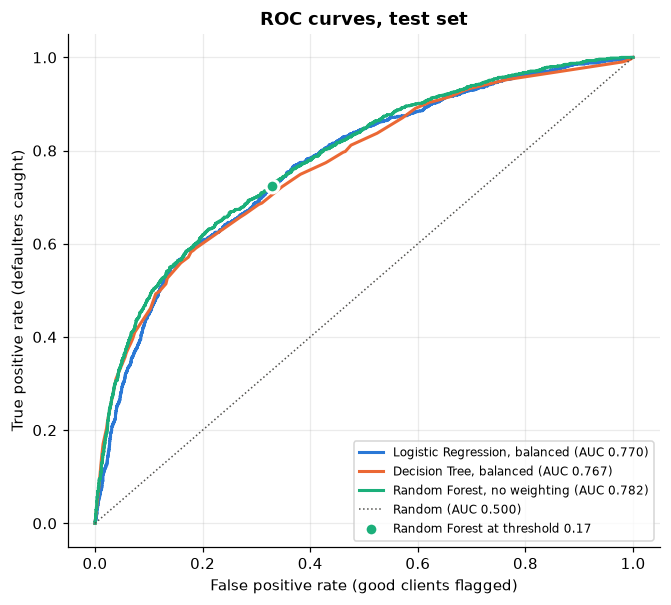

In [19]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
for name in param_grids:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax.plot(fpr, tpr, lw=2, color=MODEL_COLORS[name],
            label=f"{name}, {cw_label(SELECTED_BALANCED[name])} (AUC {roc_auc_score(y_test, test_proba[name]):.3f})")
ax.plot([0, 1], [0, 1], color="#52514e", lw=1, ls=":", label="Random (AUC 0.500)")

# Mark the chosen operating point on the best model's curve
pred_thr = (best_test_proba >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_thr).ravel()
ax.scatter([fp / (fp + tn)], [tp / (tp + fn)], s=70, color=MODEL_COLORS[BEST_MODEL], edgecolor="white",
           linewidth=2, zorder=5, label=f"{BEST_MODEL} at threshold {THRESHOLD:.2f}")
ax.set_xlabel("False positive rate (good clients flagged)")
ax.set_ylabel("True positive rate (defaulters caught)")
ax.set_title("ROC curves, test set"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "roc_test.png", bbox_inches="tight"); plt.show()

### 9.2 Confusion matrices: default threshold vs cost-based threshold

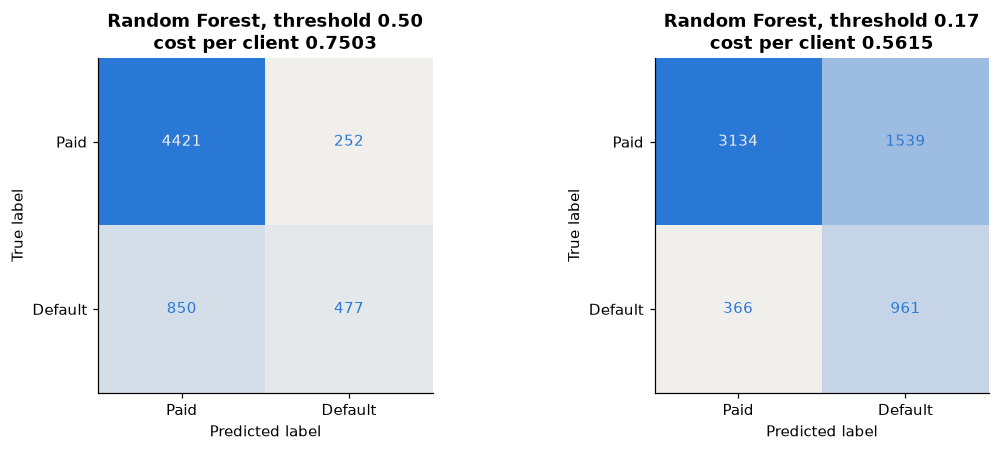

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#2a78d6"])
for ax, thr in zip(axes, [0.5, THRESHOLD]):
    pred = (best_test_proba >= thr).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Paid", "Default"]).plot(
        ax=ax, cmap=cmap, colorbar=False, values_format="d")
    ax.grid(False)
    ax.set_title(f"{BEST_MODEL}, threshold {thr:.2f}\ncost per client {cost_per_client(y_test, best_test_proba, thr):.4f}")
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices.png", bbox_inches="tight"); plt.show()

**Interpretation.** Moving from 0.50 to the cost-based threshold trades precision for recall: the bank flags more
good clients for review, but catches more of the defaulters, which under a 5:1 cost ratio lowers total expected
cost. The numbers in the table above and the matrices here come from the held-out test set, which was used
neither for tuning nor for picking the threshold.

## 10. Feature importance (best model)
**Permutation importance** on the test set: each feature is shuffled in turn and the drop in ROC-AUC is
measured. Unlike impurity-based importance it is computed on unseen data and is not biased toward
high-cardinality numeric features. One caveat: strongly correlated features share credit, so shuffling one of
them can look less important than it is because its partner still carries the information.

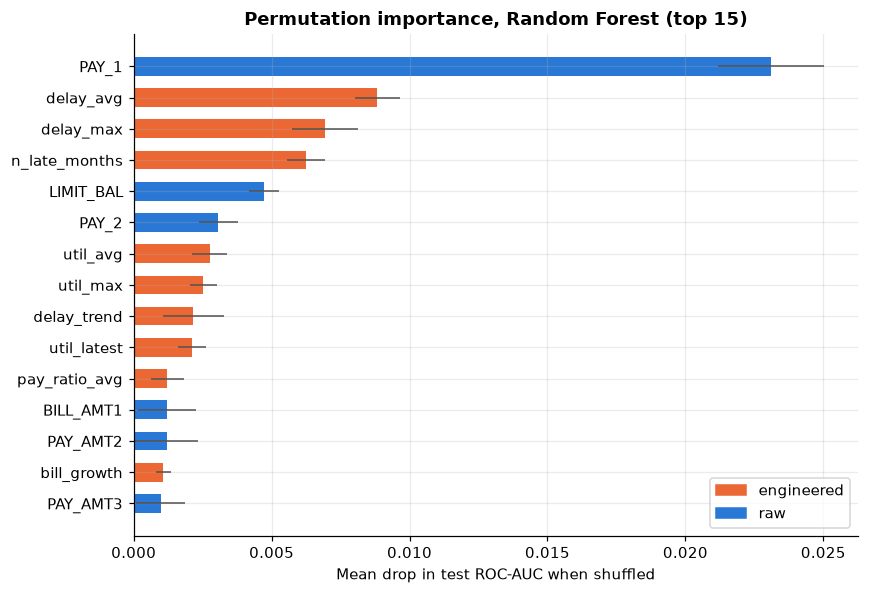

,feature,importance,std
0,PAY_1,0.0231,0.0019
1,delay_avg,0.0088,0.0008
2,delay_max,0.0069,0.0012
3,n_late_months,0.0063,0.0007
4,LIMIT_BAL,0.0047,0.0005
5,PAY_2,0.0031,0.0007
6,util_avg,0.0028,0.0006
7,util_max,0.0025,0.0005
8,delay_trend,0.0022,0.0011
9,util_latest,0.0021,0.0005


In [21]:
best_fitted = fitted[BEST_MODEL]
perm = permutation_importance(best_fitted, X_test_fe[FEATURES], y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
imp = (pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean, "std": perm.importances_std})
       .sort_values("importance", ascending=False).reset_index(drop=True))
imp.to_csv(RES_DIR / "permutation_importance.csv", index=False)

top = imp.head(15).iloc[::-1]
colors = ["#eb6834" if f in ENGINEERED else "#2a78d6" for f in top["feature"]]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color=colors, height=0.6,
        error_kw={"ecolor": "#52514e", "lw": 1})
ax.set_xlabel("Mean drop in test ROC-AUC when shuffled")
ax.set_title(f"Permutation importance, {BEST_MODEL} (top 15)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#eb6834", label="engineered"), Patch(color="#2a78d6", label="raw")], loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_importance.png", bbox_inches="tight"); plt.show()
imp.head(15).round(4)

In [22]:
# Impurity-based importance from the forest itself, for comparison (computed on training data)
clf = best_fitted.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    names = best_fitted.named_steps["prep"].get_feature_names_out()
    mdi = pd.Series(clf.feature_importances_, index=[n.split("__", 1)[1] for n in names])
    print("Impurity-based importance, top 10:")
    print(mdi.sort_values(ascending=False).head(10).round(4).to_string())

Impurity-based importance, top 10:
PAY_1            0.1607
delay_avg        0.1160
n_late_months    0.0934
delay_max        0.0766
PAY_2            0.0755
delay_trend      0.0379
PAY_3            0.0328
PAY_4            0.0268
util_max         0.0261
util_avg         0.0238


**What drives the predictions.**
* The most recent repayment status (`PAY_1`) dominates: shuffling it lowers test ROC-AUC by about 0.023, more
  than twice any other feature.
* The next three features are engineered delinquency summaries (`delay_avg`, `delay_max`, `n_late_months`),
  and 7 of the top 10 are engineered features, including the three utilization measures. The impurity-based
  ranking from the forest agrees on the leading features.
* Credit limit is the strongest non-delinquency feature, matching the EDA. Payment-ratio and bill-trend features
  contribute less; part of their information is shared with the delay and utilization features, and
  permutation importance under-credits correlated features.
* The picture is consistent with how credit risk is assessed in practice: recent and repeated delinquency first,
  then how stretched the client is relative to the limit.

## 11. Summary and limitations
The final numbers are in the tables printed above; the README summarizes them.

**Limitations**
* **Data age and scope.** One Taiwanese bank in 2005, during a local credit card debt crisis. Behaviour and
  default rates in other markets or periods may differ, so the model would need retraining and monitoring.
* **Short history.** Only six months of behaviour and no bureau data, income, or other debts, which caps
  achievable performance.
* **Cost ratio is an assumption.** 5:1 is illustrative. A real deployment would estimate loss given default and
  per-client margin and re-derive the threshold; the cost curve in Section 8 makes that easy to redo.
* **Calibration not verified.** The threshold matching 1/6 hints that the forest's probabilities are roughly
  calibrated, but no calibration curve was checked. If true probabilities are needed (for pricing or expected
  loss), check reliability and add calibration (for example `CalibratedClassifierCV`). A `balanced`-weight
  model in particular would need recalibration, because weighting shifts probabilities upward.
* **Modest absolute performance.** A test ROC-AUC around 0.78 is typical for this dataset but far from perfect:
  even at the chosen threshold a large share of flagged clients would have paid, so in practice the model
  should route clients to review or limit adjustments rather than issue automatic rejections.
* **Tuning and comparison share the training folds.** The CV comparison is therefore slightly optimistic; the
  untouched test set is the unbiased final check.
* **Fairness.** Excluding protected attributes does not guarantee fair outcomes, because other features can act
  as proxies. A production model would also need disparate-impact testing.